# 第6章 机械储能运行优化

全部参数与价格为教学构造数据。依次执行五个代码单元，完成手算、状态图、33条轨迹、工况比较和绘图。安装说明见本目录README。所有新结果写入新建临时目录。

## 1 用水量与能量账核验一次抽水

正流量填充上库，负并网电功率表示输入。20 m³/s抽水1 h，输入49.14193 MWh。

In [1]:
from pathlib import Path
import sys, tempfile, json, importlib.util
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch06/run.py").exists())
chapter = root / "chapters/ch06"
sys.path.insert(0, str(chapter))
spec = importlib.util.spec_from_file_location("ch06_model", chapter / "run.py")
model = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = model
spec.loader.exec_module(model)
step = model.transition(576000, 20)
for key in ["end", "head", "power", "delta_u", "hydraulic_loss", "conversion_loss"]:
    print(key, round(step[key], 8))
assert abs(-step["power"] - step["delta_u"] - step["hydraulic_loss"] - step["conversion_loss"]) < 1e-8

end 648000.0
head 221.25
power -49.14193154
delta_u 43.40925
hydraulic_loss 0.07848
conversion_loss 5.65420154


## 2 从状态到有限网格动态规划

基础状态包括水量索引与上一流量档位。返回值说明网格范围内的最优性。

In [2]:
edges = model.graph()
print("状态数：", len(edges))
solution = model.plan(model.prices())
print("求解状态：", solution["status"])
print("有限网格目标 / 元：", round(solution["objective_cny"], 6))
print("评估边数：", solution["evaluated_edges"])
print("流量：", solution["flow"])
assert solution["status"] == "optimal_on_grid"
assert solution["flow"][-1] == 0

状态数： 107
求解状态： optimal_on_grid
有限网格目标 / 元： 259185.498126
评估边数： 4559
流量： [20.0, 40.0, 40.0, 40.0, 20.0, 0.0, 0.0, -20.0, -40.0, -20.0, 0.0, 0.0, 20.0, 40.0, 20.0, 0.0, -20.0, -40.0, -60.0, -40.0, -20.0, 0.0, 20.0, 0.0]


## 3 计算并保存全部33条轨迹

每条计划保持原流量，在统一物理模型中回放。失败案例也随输出保存。

In [3]:
work = tempfile.TemporaryDirectory(prefix="ch06_notebook_")
out = Path(work.name) / "experiment"
data = model.experiment()
summary = model.write_outputs(out, data)
print("完整轨迹：", len(data["runs"]))
print("逐时记录：", sum(len(r["flow"]) for r in data["runs"]))
print("目标不可达：", data["failures"][0]["result"]["status"])
assert len(data["runs"]) == 33
assert data["failures"][0]["result"]["status"] == "infeasible"

完整轨迹： 33
逐时记录： 792
目标不可达： infeasible


## 4 将收益、约束与末端库存共同解释

近似模型的收益与越限记录一起保存。放开末端水量后，库存变化进入能量账，循环效率为空。

In [4]:
for run in data["runs"]:
    if run["scenario"] == "solar":
        print(run["policy"], round(run["metrics"]["profit_cny"], 2), run["violations"])
free = next(r for r in data["runs"] if r["group"] == "free_terminal")
m = free["metrics"]
print("自由末端势能变化 / MWh：", m["delta_storage_mwh"])
print("输出输入比 / 循环效率：", m["energy_output_input_ratio"], m["round_trip_efficiency"])
assert m["round_trip_efficiency"] is None
assert abs(m["delta_storage_mwh"] + 329.616) < 1e-8
for run in data["runs"]:
    x = run["metrics"]
    residual = x["pump_energy_mwh"]-x["generation_energy_mwh"]-x["delta_storage_mwh"]-x["hydraulic_loss_mwh"]-x["conversion_loss_mwh"]
    assert abs(residual) < 1e-7
print("33条整日能量账均闭合。")

rule 251232.41 []
fixed 414413.32 [{'hour': 13, 'constraint': 'pump_power', 'value': 155.03540245765524, 'limit': 150.0, 'excess': 5.035402457655238}]
head 397382.44 [{'hour': 12, 'constraint': 'pump_power', 'value': 151.29717018880422, 'limit': 150.0, 'excess': 1.2971701888042162}]
full 403244.59 []
自由末端势能变化 / MWh： -329.616
输出输入比 / 循环效率： 1.2829304798115724 None
33条整日能量账均闭合。


## 5 从同一结果生成精细彩图

重绘5幅定量图，导出SVG、PDF和600 dpi PNG；示例显示计划与回放及红色越限标记。

5幅定量图已生成。独立核验：python chapters/ch06/verify.py


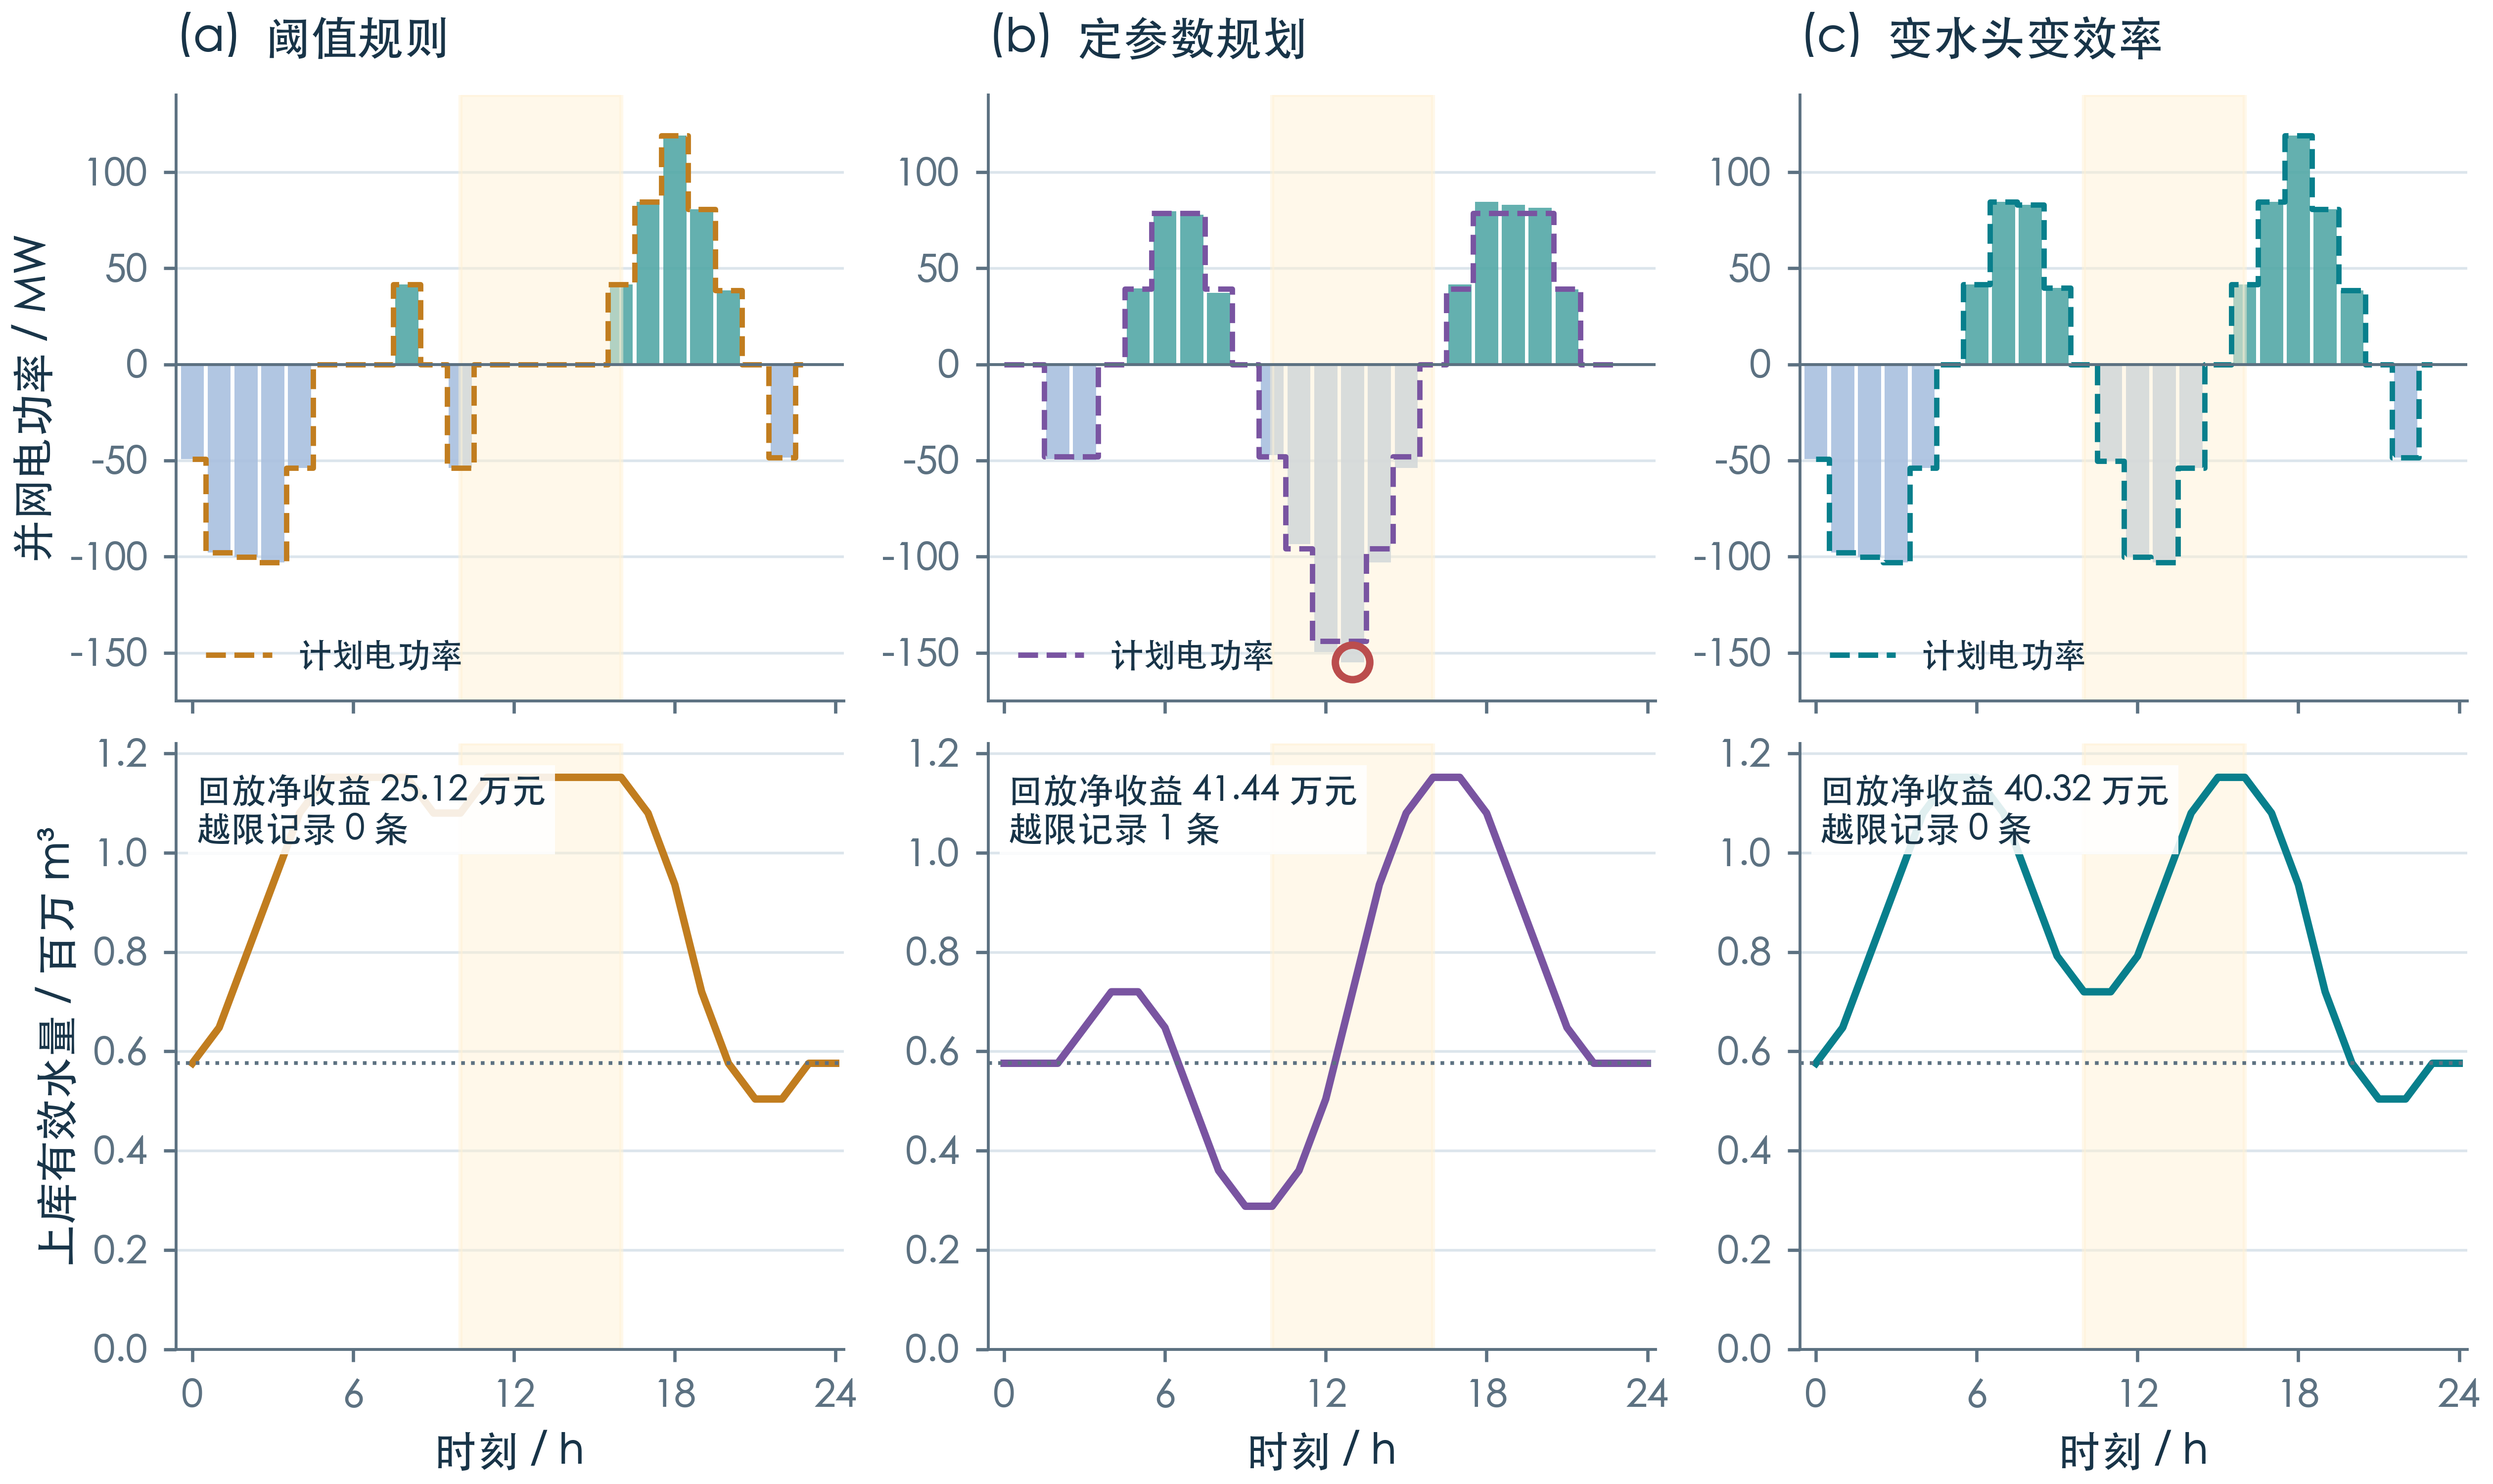

In [5]:
from plot_results import draw
from IPython.display import Image, display
draw(data, out / "figures")
display(Image(filename=str(out / "figures/fig6_5_dispatch.png"), width=950))
print("5幅定量图已生成。独立核验：python chapters/ch06/verify.py")

## 继续实验

在新的Config中改变功率变化上限或流量网格，记录所有工况。解释初末库存及求解状态，保存越限轨迹和原始基线。压缩空气扩展需增加质量、温度、压力及储热状态，先建立手算基准。